# Q1

In [12]:

import pandas as pd

# Import data from CSV file
df = pd.read_csv("salary.csv")

print("Imported Data:")
print(df)

# Export data to CSV file
df.to_csv("output.csv", index=False)

print("Data exported successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'salary.csv'

In [27]:

import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.datasets import load_iris
data=load_iris(as_frame=True)
data.frame

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


# Q2

In [29]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# Load Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame

X = df.drop('target', axis=1)

print("Original Dataset:")
print(df.head())

# 1. Standardization
sc = StandardScaler()
standardized = sc.fit_transform(X)

print("\nStandardization:")
print(pd.DataFrame(standardized, columns=X.columns).head())

# 2. Normalization
mm = MinMaxScaler()
normalized = mm.fit_transform(X)

print("\nNormalization:")
print(pd.DataFrame(normalized, columns=X.columns).head())

# 3. Summarization
print("\nSummarization:")
print(df.describe())

# 4. De-duplication
print("\nDe-duplication:")
print("Before:", df.duplicated().sum())

df = df.drop_duplicates()

print("After:", df.duplicated().sum())

# 5. Imputation
print("\nImputation:")

# Introduce missing values
df.loc[0, 'sepal length (cm)'] = None
df.loc[1, 'petal length (cm)'] = None

print("\nBefore Imputation:")
print(df.isnull().sum())

# Apply SimpleImputer
imputer = SimpleImputer(strategy='mean')

df.iloc[:, :-1] = imputer.fit_transform(df.iloc[:, :-1])

print("\nAfter Imputation:")
print(df.isnull().sum())

print("\nFinal Dataset:")
print(df.head())

Original Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Standardization:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.24920

In [28]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,Standardized,Normalized
0,5.1,3.5,1.4,0.2,0,-0.900681,0.222222
1,4.9,3.0,1.4,0.2,0,-1.143017,0.166667
2,4.7,3.2,1.3,0.2,0,-1.385353,0.111111
3,4.6,3.1,1.5,0.2,0,-1.506521,0.083333
4,5.0,3.6,1.4,0.2,0,-1.021849,0.194444
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,1.038005,0.666667
146,6.3,2.5,5.0,1.9,2,0.553333,0.555556
147,6.5,3.0,5.2,2.0,2,0.795669,0.611111
148,6.2,3.4,5.4,2.3,2,0.432165,0.527778


# candidate elimination method

In [ ]:
# Candidate Elimination Algorithm

x = [
    ['Sunny', 'Warm', 'Normal', 'Strong'],
    ['Sunny', 'Warm', 'High', 'Strong'],
    ['Rainy', 'Cold', 'High', 'Strong'],
    ['Sunny', 'Warm', 'High', 'Weak']
]
y = ['Yes', 'Yes', 'No', 'Yes']
S = ['na']*len(x[0])
G=[['?']* len(x[0])]
for i in range(len(x)):
    if ( y[i]=='Yes'):
        for j in range(len(S)):
            if S[j] == 'na':
                S[j]=x[i][j]
            elif S[j] !=x[i][j] :
                S[j] = "?"
        new_G=[]
        for g in G :
            match=True
            for j in range(len(S)):
                if g[j] !="?" and g[j] !=x[i][j]:
                    match=False
                    break
            if match :
                new_G.append(g)
        G=new_G
    else:
        new_G=[]
        for g in G :
            match =True
            for j in range(len(S)):
                if g[j] !="?" and  g[j]!=x[i][j]:
                    match=False
                    break
            
            if not match :
                new_G.append(g)
            else:
                for j in range(len(S)):
                    if S[j] !="?" and S[j] !="na" and S[j] !=x[i][j] and g[j]=="?" :
                        h=g.copy()
                        h[j]=S[j]
                        new_G.append(h)
        G=new_G
print(S)
print(G)

S = ['Sunny', 'Warm', '?', '?']
G = [['Sunny', '?', '?', '?'], ['?', 'Warm', '?', '?']]


# Q4


 Linear
MSE: 0.48969696969696985
MAE: 0.5418181818181818
R2 Score: 0.9446044151926505


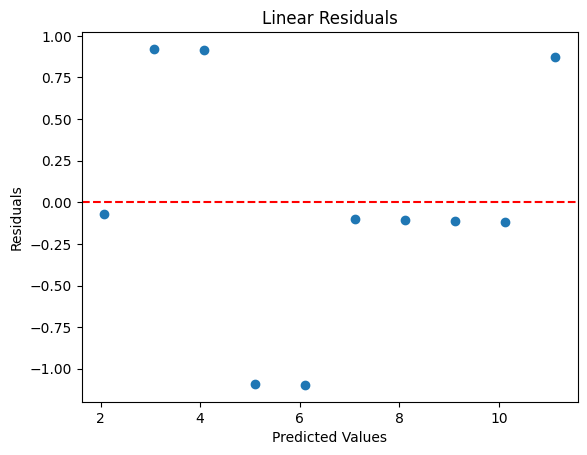


 Polynomial
MSE: 0.34121212121212136
MAE: 0.4993939393939396
R2 Score: 0.9614013437542849


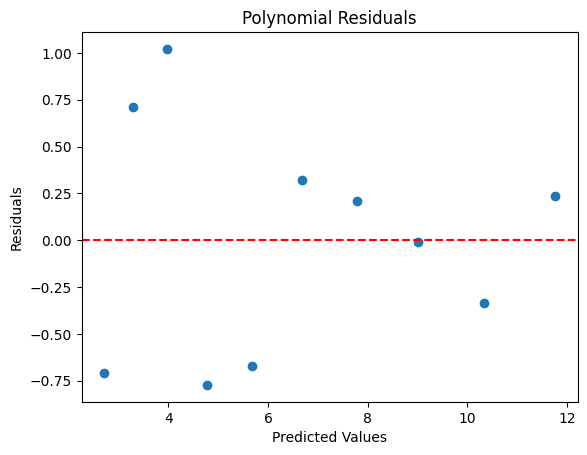


 Ridge
MSE: 0.343942357821589
MAE: 0.5028607305092884
R2 Score: 0.9610924934590963


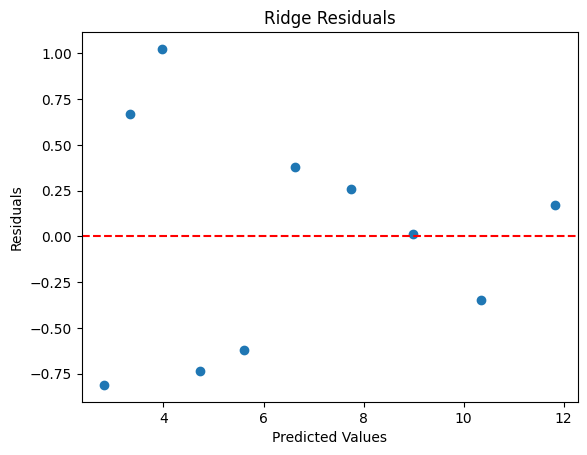


 Lasso
MSE: 0.3612968372362485
MAE: 0.5124005791112469
R2 Score: 0.959129317054723


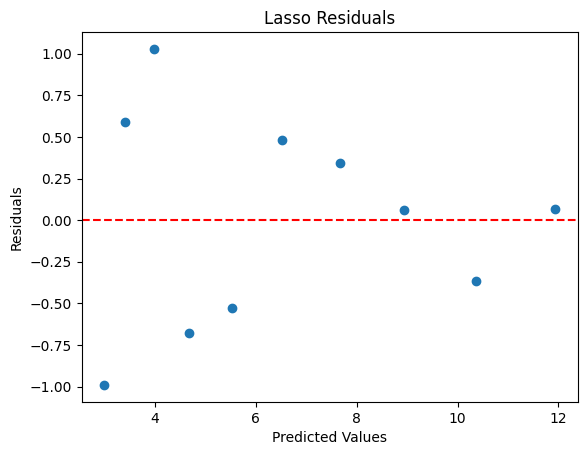

Linear Predictions: [12.13333333 13.13939394]
Polynomial Predictions: [13.3        14.94242424]
Ridge Predictions: [13.43127747 15.15358792]
Lasso Predictions: [13.64940612 15.50662118]


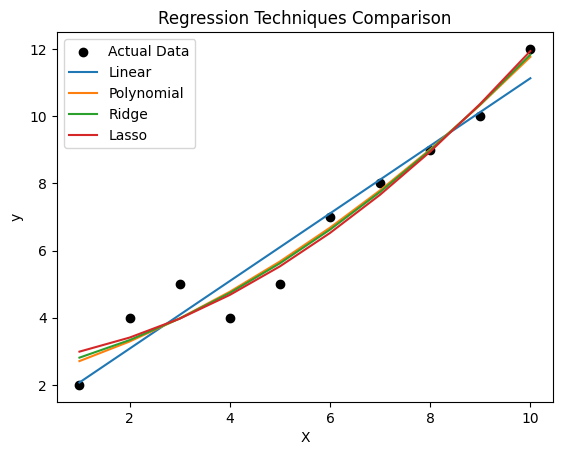

In [168]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([2, 4, 5, 4, 5, 7, 8, 9, 10, 12])

# Models
models = {
    "Linear": LinearRegression(),
    "Polynomial": Pipeline([
        ("poly", PolynomialFeatures(degree=2)),
        ("lr", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("poly", PolynomialFeatures(degree=2)),
        ("ri", Ridge(alpha=1.0))
    ]),
    "Lasso": Pipeline([
        ("poly", PolynomialFeatures(degree=2)),
        ("la", Lasso(alpha=0.1, max_iter=10000))
    ])
}

# Fit and evaluate
for name, model in models.items():
    model.fit(X, y)
    pred = model.predict(X)
    residuals = y - pred

    print("\n", name)
    print("MSE:", mean_squared_error(y, pred))
    print("MAE:", mean_absolute_error(y, pred))
    print("R2 Score:", r2_score(y, pred))

    plt.figure()
    plt.scatter(pred, residuals)
    plt.axhline(0, color="red", linestyle="--")
    plt.title(name + " Residuals")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.show()

# Predict at unknown locations
X_new = np.array([11, 12]).reshape(-1, 1)

for name, model in models.items():
    print(name, "Predictions:", model.predict(X_new))

# Final visualization: Regression lines
plt.scatter(X, y, color="black", label="Actual Data")

for name, model in models.items():
    plt.plot(X, model.predict(X), label=name)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regression Techniques Comparison")
plt.legend()
plt.show()


# 5

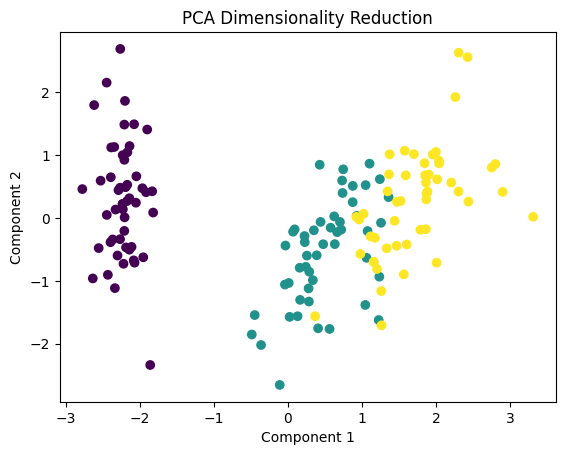

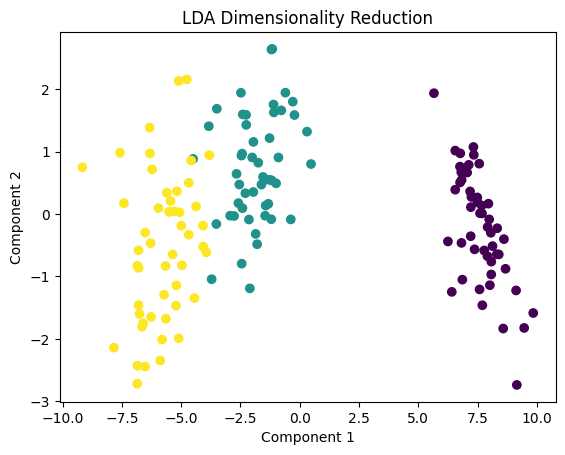

Original dimensions: (150, 4)
PCA dimensions: (150, 2)
LDA dimensions: (150, 2)
PCA explained variance: [0.72962445 0.22850762]


In [33]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Load dataset
data = load_iris()
X = data.data
y = data.target

# Standardize data
X = StandardScaler().fit_transform(X)

# PCA dimensionality reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# LDA dimensionality reduction
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X, y)

# Visualize PCA
plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.title("PCA Dimensionality Reduction")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

# Visualize LDA
plt.figure()
plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y)
plt.title("LDA Dimensionality Reduction")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

# Display dimensions
print("Original dimensions:", data.data.shape)
print("PCA dimensions:", X_pca.shape)
print("LDA dimensions:", X_lda.shape)
print("PCA explained variance:", pca.explained_variance_ratio_)


In [35]:
data.feature_names,data.target_names

(['sepal length (cm)',
  'sepal width (cm)',
  'petal length (cm)',
  'petal width (cm)'],
 array(['setosa', 'versicolor', 'virginica'], dtype='<U10'))

# 6

In [183]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = load_iris()
X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize data
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Create K-NN model
model = KNeighborsClassifier(n_neighbors=3)

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Predict a new sample
sample = sc.transform([[5.1, 3.5, 1.4, 0.2]])
print("Predicted class:", model.predict(sample))


Accuracy: 1.0
Predicted class: [0]


# 7

In [201]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

data = pd.read_csv("german.csv")
X = data.drop("status", axis=1)
y = data["status"]

X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Logistic Regression
m1 = LogisticRegression(max_iter=1000)
m1.fit(X_train, y_train)
p1 = m1.predict(X_test)
print("Logistic Regression")
print(confusion_matrix(y_test, p1))
print("Accuracy:", accuracy_score(y_test, p1))

# SVM
m2 = SVC()
m2.fit(X_train, y_train)
p2 = m2.predict(X_test)
print("\nSVM")
print(confusion_matrix(y_test, p2))
print("Accuracy:", accuracy_score(y_test, p2))

# Naive Bayes
m3 = GaussianNB()
m3.fit(X_train, y_train)
p3 = m3.predict(X_test)
print("\nNaive Bayes")
print(confusion_matrix(y_test, p3))
print("Accuracy:", accuracy_score(y_test, p3))


Logistic Regression
[[194  15]
 [ 53  38]]
Accuracy: 0.7733333333333333

SVM
[[209   0]
 [ 86   5]]
Accuracy: 0.7133333333333334

Naive Bayes
[[167  42]
 [ 34  57]]
Accuracy: 0.7466666666666667


c:\Users\THIS PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# 8

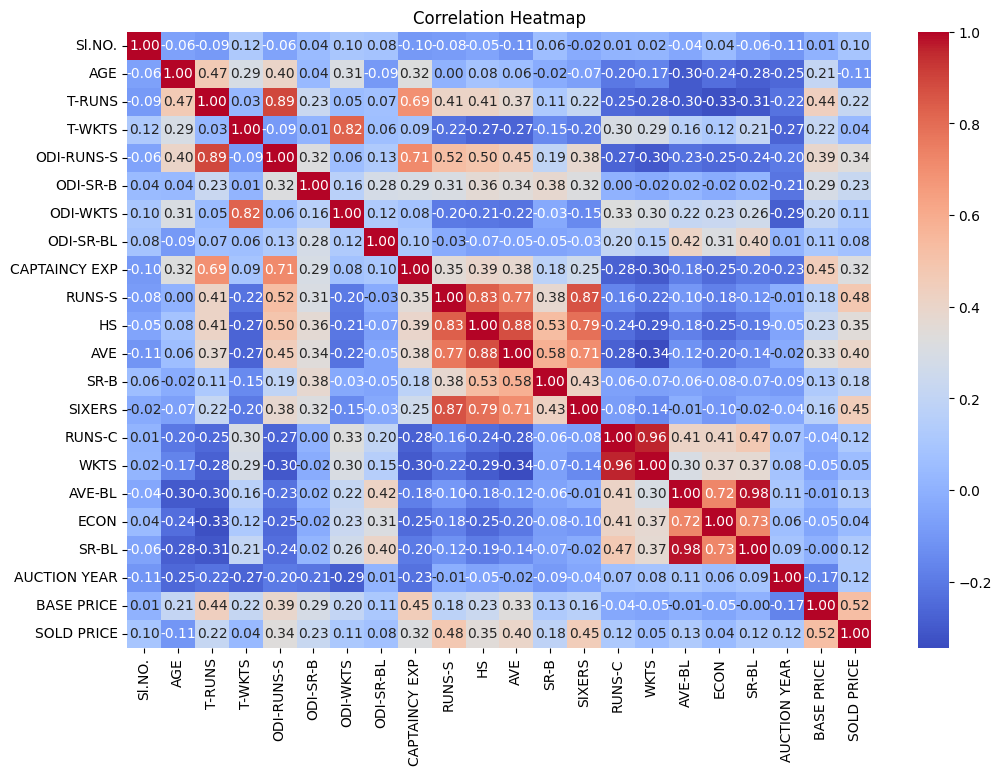

Training RMSE: 2.5040047283829708e-05
Testing RMSE: 287647.8981876559


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Load dataset
data = pd.read_csv("IPL IMB381IPL2013.csv")

# Correlation matrix of numeric features
corr = data.select_dtypes(include="number").corr()

# Visualize heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f",cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Separate input and target
X = data.drop("SOLD PRICE", axis=1)
y = data["SOLD PRICE"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict prices
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)


# 9

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load dataset
data = pd.read_csv("spam (1).csv")

# Select message and label columns
X = data["v2"]
y = data["v1"]

# Convert text into numeric features
cv = CountVectorizer()
X = cv.fit_transform(X)
print(X.toarray())
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict spam or ham
y_pred = model.predict(X_test)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Test a new email
email = ["Congratulations! You have won a free prize"]
email = cv.transform(email)
print("Prediction:", model.predict(email)[0])


[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 1 1 0]
 ...
 [1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Accuracy: 1.0
Prediction: spam


## 15

In [11]:
import pandas as pd

# Dataset
data = pd.DataFrame({
    "Weather": ["Sunny", "Rainy", "Sunny", "Cloudy",
                "Rainy", "Sunny", "Cloudy", "Rainy"],
    "Play": ["Yes", "No", "Yes", "Yes",
             "No", "Yes", "Yes", "No"]
})

# Calculate prior probabilities
prior = data["Play"].value_counts(normalize=True)
print(data)
print("Prior Probabilities:")
print(prior)

  Weather Play
0   Sunny  Yes
1   Rainy   No
2   Sunny  Yes
3  Cloudy  Yes
4   Rainy   No
5   Sunny  Yes
6  Cloudy  Yes
7   Rainy   No
Prior Probabilities:
Play
Yes    0.625
No     0.375
Name: proportion, dtype: float64


# 13

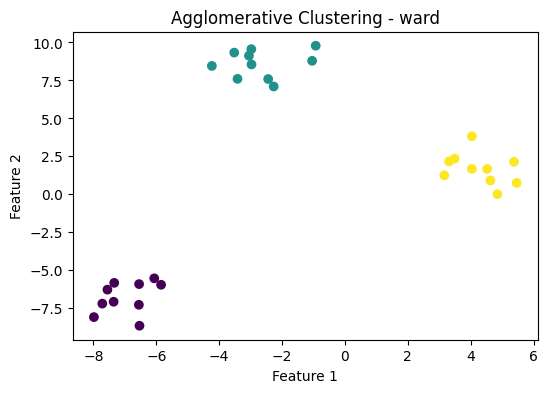

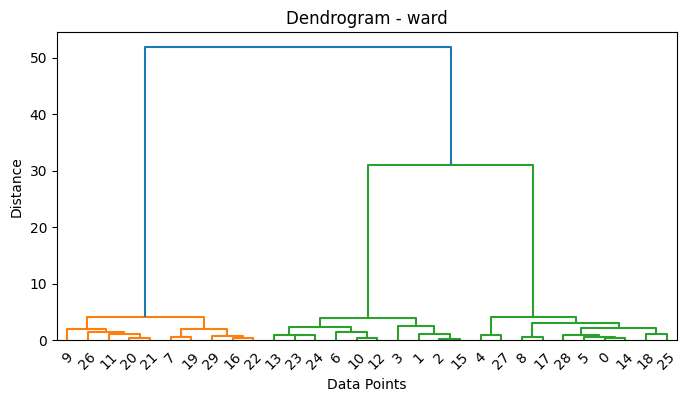

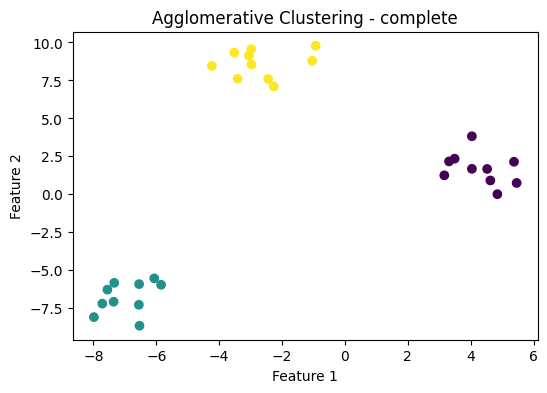

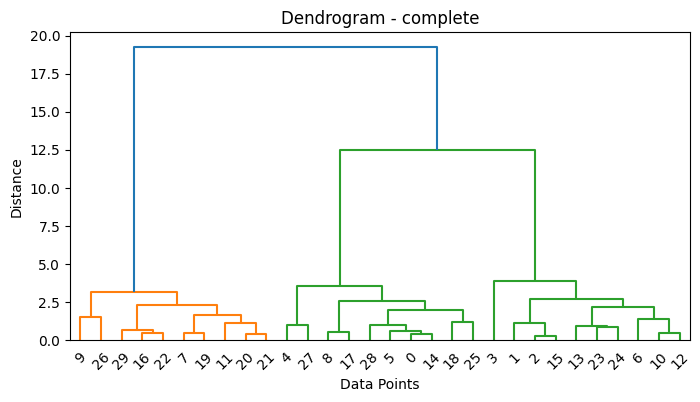

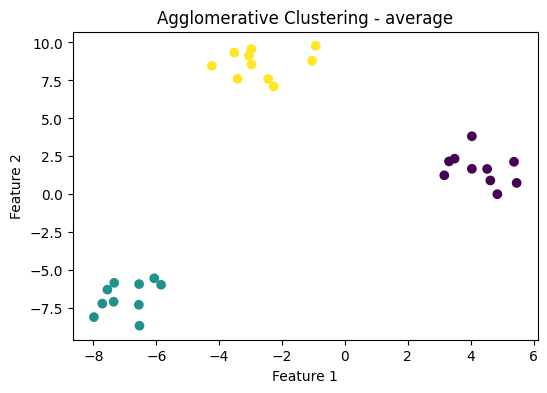

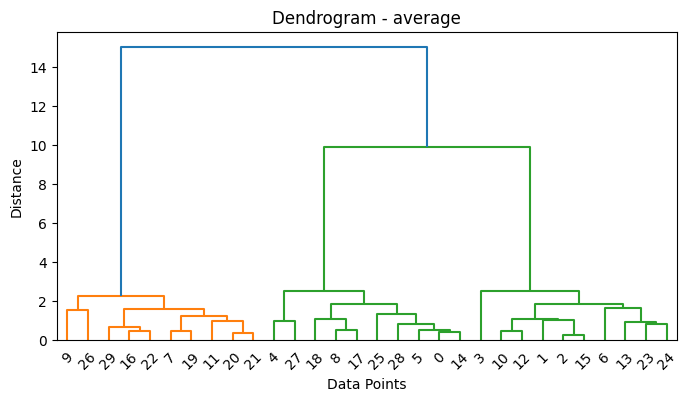

In [ ]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Create dataset
X, y = make_blobs(n_samples=30, centers=3, random_state=42)

methods = ['ward', 'complete', 'average']

for method in methods:

    # Apply Agglomerative Clustering algorithm
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )
    model.fit(X)
    labels=model.predict(X)

    # Plot clusters
    plt.figure(figsize=(6, 4))
    plt.scatter(X[:, 0], X[:, 1], c=labels)
    plt.title("Agglomerative Clustering - " + method)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

    # Draw dendrogram
    Z = linkage(X, method=method)
    plt.figure(figsize=(8, 4))
    dendrogram(Z)
    plt.title("Dendrogram - " + method)
    plt.xlabel("Data Points")
    plt.ylabel("Distance")
    plt.show()


# 12

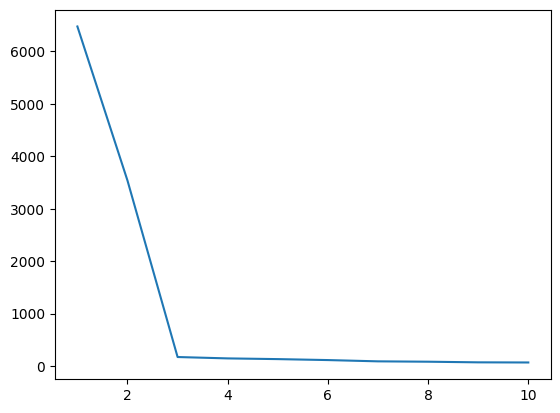

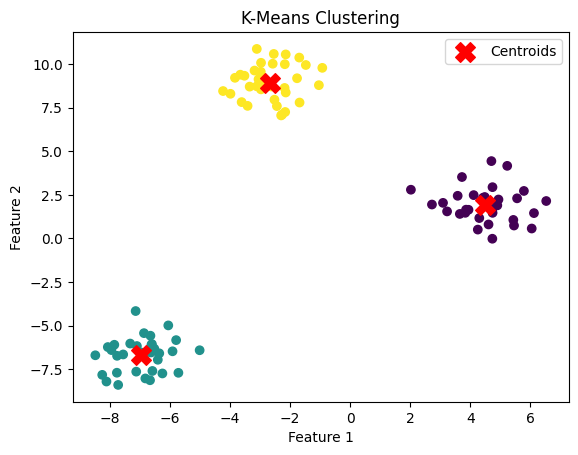

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

x,y = make_blobs(n_samples=100,random_state=42,centers=3)

wcss=[]
for i in range(1,11):
    km=KMeans(n_clusters=i )
    y_pred=km.fit_predict(x)
    wcss.append(km.inertia_)
plt.plot(range(1,11),wcss)


km=KMeans(n_clusters=3)
y_pred=km.fit_predict(x)

plt.figure()
plt.scatter(x[:,0],x[:,1],c=y_pred)
centers=km.cluster_centers_
plt.scatter(centers[:,0],centers[:,1], color='red', marker='X', s=200,
            label='Centroids')
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [53]:
km.inertia_

1851.999926975514

# 10

Gini Accuracy: 0.7209302325581395
Entropy Accuracy: 0.7674418604651163


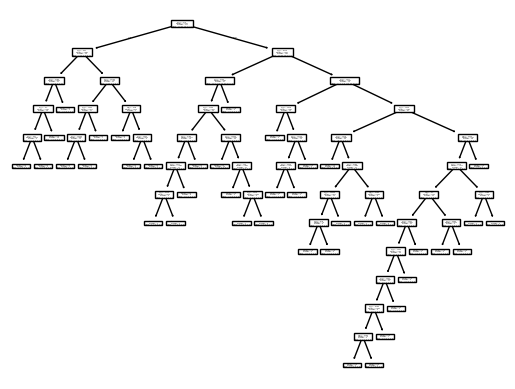

In [38]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score

# Load dataset
data = pd.read_csv("glass identification.csv")

# Split features and target
X = data.drop("Type", axis=1)
y = data["Type"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Decision Tree using Gini Index
model1 = DecisionTreeClassifier(criterion="gini", random_state=42)
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)

print("Gini Accuracy:", accuracy_score(y_test, pred1))

# Decision Tree using Entropy
model2 = DecisionTreeClassifier(criterion="entropy", random_state=42)
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)
plot_tree(model2)

print("Entropy Accuracy:", accuracy_score(y_test, pred2))


# 16

In [39]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Sample patient dataset
data = pd.DataFrame({
    'Fever': [1, 1, 0, 0, 1, 0, 1, 0],
    'Cough': [1, 0, 1, 0, 1, 0, 0, 1],
    'Fatigue': [1, 1, 0, 0, 1, 0, 1, 0],
    'Illness': [1, 1, 0, 0, 1, 0, 1, 0]
})

X = data[['Fever', 'Cough', 'Fatigue']]
y = data['Illness']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Train model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)
print(predictions)
print("Accuracy:", accuracy_score(y_test, predictions))
print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))

# Predict for a new patient
patient =pd.DataFrame([[1, 1, 0]],columns=X.columns)
result = model.predict(patient)

print("Predicted Illness:", "Yes" if result[0] == 1 else "No")


[0 1]
Accuracy: 1.0
Confusion Matrix:
 [[1 0]
 [0 1]]
Predicted Illness: No


In [10]:
data

,Fever,Cough,Fatigue,Illness
0,1,1,1,1
1,1,0,1,1
2,0,1,0,0
3,0,0,0,0
4,1,1,1,1
5,0,0,0,0
6,1,0,1,1
7,0,1,0,0


# 14

In [ ]:

import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Download dataset from OpenML
data = fetch_openml(
    name="creditcard",
    version=1,
    as_frame=True
)


# Convert dataset into DataFrame
df =pd.read_csv("./creditcard.csv")
df.to_csv("creditcard.csv")
# Display dataset
print(df.head())

# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict fraud transactions
y_pred = model.predict(X_test)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Display actual and predicted values
result = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(result.head(10))


   Unnamed: 0        V1        V2        V3        V4        V5        V6  \
0           0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388   
1           1  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361   
2           2 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499   
3           3 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203   
4           4 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921   

         V7        V8        V9  ...       V21       V22       V23       V24  \
0  0.239599  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928   
1 -0.078803  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846   
2  0.791461  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281   
3  0.237609  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575   
4  0.592941 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267   

        V25       V26       V27       V28  Amount  Class

In [7]:
df.head()

,Unnamed: 0,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# 11

[0.10556084 0.12574385 0.18555001 0.1244297  0.08219454 0.13550001
 0.14421436 0.07817407 0.01863261]


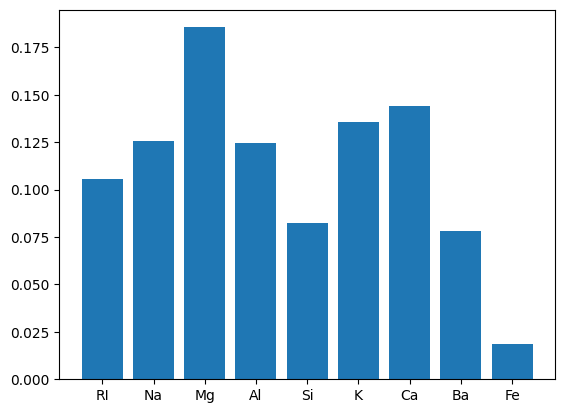

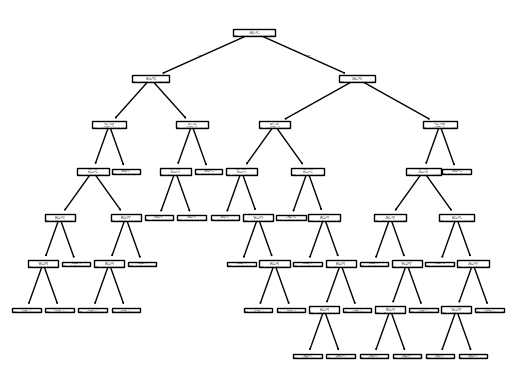

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree
import pandas as pd
import matplotlib.pyplot as plt
# Load dataset
data = pd.read_csv("glass identification.csv")
X = data.drop("Type", axis=1)
y = data["Type"]


# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model=RandomForestClassifier(
    n_estimators=100,random_state=42,class_weight='balanced'
)
model.fit(X_train,y_train)
print(model.feature_importances_)
plt.figure()
plt.bar(X.columns,model.feature_importances_)
plt.figure()
plot_tree(model.estimators_[0])
plt.show()